# EDA de precios del maíz blanco | Cobertura y faltantes

## 1 | La preguntita inicial
¿Qué información tenemos disponible por mes, mercado y origen
durante la ventana de 2013–2025?

Cada fila representa un mes, un mercado y un origen del maíz.
El precio está expresado en pesos mexicanos por kilogramo.
Los precios faltantes se conservarán, de momento, sin imputación.

### 1.1 | Carga de los datos y primeras observaciones

In [1]:
from pathlib import Path

import pandas as pd

# Ubicamos la raíz desde el repositorio o desde notebooks.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

# Cargamos los datos y reconocemos la fecha como tal.
ruta = raiz / "data" / "processed" / "sniim_maiz_blanco_mensual.csv"
datos = pd.read_csv(ruta, parse_dates=["fecha"])

# Observamos las primeras filas, sin transformar los precios.
datos.head(10)

,fecha,estado_mercado,mercado,origen,producto,precio_mxn_kg
0,2013-01-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.36
1,2013-02-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.00
2,2013-03-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.50
3,2013-04-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,6.24
4,2013-05-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.62
5,2013-06-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.30
6,2013-07-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.56
7,2013-08-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.40
8,2013-09-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.32
9,2013-10-01,Sonora,Hermosillo,Sinaloa,Maíz blanco,5.72


## 2 | Estructura general de los datos

¿Cuántas observaciones y columnas tenemos?
¿Qué tipos de datos tienen las columnas y cuántos valores
están presentes en cada una?

### 2.1 | Dimensiones, tipos de datos y valores presentes

In [2]:
# Revisamos dimensiones, tipos y cantidad de valores presentes.
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 960 entries, 0 to 959
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   fecha           960 non-null    datetime64[us]
 1   estado_mercado  960 non-null    str           
 2   mercado         960 non-null    str           
 3   origen          960 non-null    str           
 4   producto        960 non-null    str           
 5   precio_mxn_kg   791 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(4)
memory usage: 81.7 KB


### 2.2 | Observación inicial

El conjunto contiene 960 observaciones y seis columnas.
Cada observación corresponde a un mes, mercado y origen.

La única columna con valores faltantes es `precio_mxn_kg`:
tiene 791 precios presentes y 169 faltantes (17.6 %).

Este conteo todavía no distingue entre un origen sin precio
y un mercado sin ningún precio disponible durante un mes.

### 2.3 | Periodo de estudio y mercados incluidos

In [3]:
# Identificamos el periodo y los mercados presentes.
print("Primera fecha:", datos["fecha"].min().date())
print("Última fecha:", datos["fecha"].max().date())
print("Meses distintos:", datos["fecha"].nunique())
print("Mercados:", sorted(datos["mercado"].unique()))

Primera fecha: 2013-01-01
Última fecha: 2025-12-01
Meses distintos: 156
Mercados: ['Culiacán', 'Guadalajara', 'Guadalupe', 'Hermosillo', 'Iztapalapa']


## 3 | Cobertura por mercado

¿Cuántos meses aparecen para cada mercado y cuántos precios
están disponibles?

Un mercado puede tener varias filas en un mismo mes cuando
se registran distintos orígenes del maíz de manera simultánea.

### 3.1 | Conteo de filas, meses y precios por mercado

In [4]:
# Resumimos las filas, los meses y los precios por mercado.
resumen_mercados = datos.groupby("mercado").agg(
    filas=("fecha", "size"),
    meses_registrados=("fecha", "nunique"),
    precios_presentes=("precio_mxn_kg", "count"),
)

# Calculamos cuántas filas tienen el precio vacío.
resumen_mercados["precios_faltantes"] = (
    resumen_mercados["filas"] - resumen_mercados["precios_presentes"]
)

resumen_mercados

,filas,meses_registrados,precios_presentes,precios_faltantes
mercado,,,,
Culiacán,204,156,160,44
Guadalajara,192,156,158,34
Guadalupe,216,156,166,50
Hermosillo,168,156,151,17
Iztapalapa,180,156,156,24


### 3.2 | Disponibilidad de precios por mercado y mes

In [5]:
# Contamos precios disponibles entre los orígenes de cada mercado y mes.
cobertura_mensual = (
    datos.groupby(["mercado", "fecha"])
    .agg(numero_precios=("precio_mxn_kg", "count"))
    .reset_index()
)

# Identificamos los meses sin ningún precio disponible.
meses_sin_precio = cobertura_mensual.loc[
    cobertura_mensual["numero_precios"] == 0
].copy()

print(meses_sin_precio)
print(f"Se tienen {len(meses_sin_precio)} meses sin precio alguno")

         mercado      fecha  numero_precios
89      Culiacán 2020-06-01               0
245  Guadalajara 2020-06-01               0
401    Guadalupe 2020-06-01               0
402    Guadalupe 2020-07-01               0
536   Hermosillo 2018-09-01               0
537   Hermosillo 2018-10-01               0
538   Hermosillo 2018-11-01               0
539   Hermosillo 2018-12-01               0
540   Hermosillo 2019-01-01               0
557   Hermosillo 2020-06-01               0
713   Iztapalapa 2020-06-01               0
720   Iztapalapa 2021-01-01               0
Se tienen 12 meses sin precio alguno


#### 3.2.1 | Hallazgo sobre los datos faltantes

Al considerar todos los orígenes de cada mercado, se identifican
12 combinaciones mercado–mes sin ningún precio disponible.

Hermosillo presenta cinco meses consecutivos sin precio,
de septiembre de 2018 a enero de 2019. También destaca la
ausencia simultánea de precios en los cinco mercados en junio
de 2020.

Estos huecos se conservarán, de momento, como faltantes en el análisis
principal. Su causa no puede determinarse únicamente con
los archivos disponibles.

Si bien, son pocos datos faltantes significativos a priori entre sí, al expandir un estudio utilizando esta misma arquitectura necesitaría de una estructura de analizar descriptivamente esos espacios vacíos.

### 3.3 | Proporción de meses sin precio

In [6]:
# Marcamos los meses que no tienen ningún precio disponible.
cobertura_mensual["sin_precio"] = (
    cobertura_mensual["numero_precios"] == 0
)

# Contamos meses registrados y meses sin precio por mercado.
resumen_cobertura = cobertura_mensual.groupby("mercado").agg(
    meses_registrados=("fecha", "nunique"),
    meses_sin_precio=("sin_precio", "sum"),
)

# Expresamos los meses sin precio como porcentaje de los registrados.
resumen_cobertura["porcentaje_sin_precio"] = (
    100
    * resumen_cobertura["meses_sin_precio"]
    / resumen_cobertura["meses_registrados"]
)

resumen_cobertura.round(2)

,meses_registrados,meses_sin_precio,porcentaje_sin_precio
mercado,,,
Culiacán,156,1,0.64
Guadalajara,156,1,0.64
Guadalupe,156,2,1.28
Hermosillo,156,6,3.85
Iztapalapa,156,2,1.28


### 3.4 | Visualización de la disponibilidad mensual

¿Los meses sin precio aparecen aislados, consecutivos o
simultáneamente en varios mercados?

Cada celda representa un mercado y un mes. Los colores
indican si existe al menos un precio disponible.

#### 3.4.1 | Vista completa del periodo

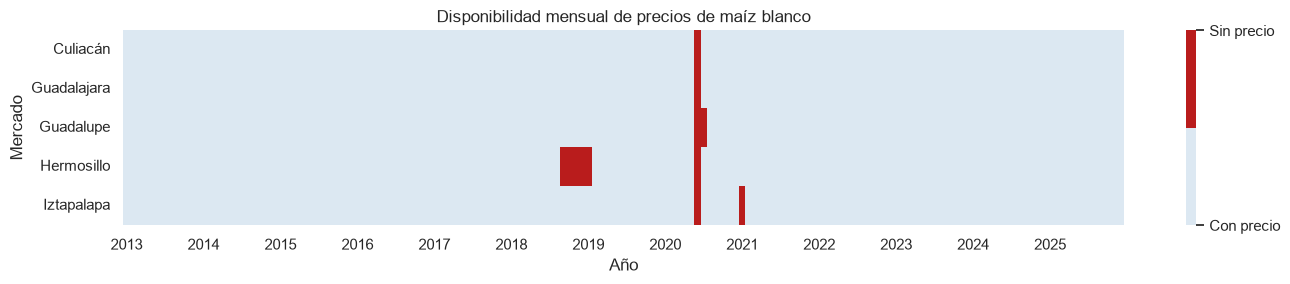

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Organizamos los faltantes en filas de mercados y columnas de meses.
matriz_faltantes = cobertura_mensual.pivot(
    index="mercado",
    columns="fecha",
    values="sin_precio",
).sort_index(axis=1)

# Dibujamos la disponibilidad: cero indica presencia y uno ausencia.
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(14, 3))

sns.heatmap(
    matriz_faltantes.astype(int),
    cmap=["#dce8f2", "#b91c1c"],
    vmin=0,
    vmax=1,
    xticklabels=12,
    yticklabels=True,
    cbar_kws={"ticks": [0, 1]},
    ax=ax,
)

# Etiquetamos los años y explicamos los colores.
ax.set_xticklabels(
    matriz_faltantes.columns[::12].strftime("%Y"),
    rotation=0,
)
ax.tick_params(axis="y", labelrotation=0)
ax.set_title("Disponibilidad mensual de precios de maíz blanco")
ax.set_xlabel("Año")
ax.set_ylabel("Mercado")

barra = ax.collections[0].colorbar
barra.set_ticklabels(["Con precio", "Sin precio"])

fig.tight_layout()
plt.show()

#### 3.4.2 | Detalle mensual de los años con faltantes

Como los faltantes están concentrados en una ventana central del rango, veamos la misma gráfica pero por año desmenuzando por mes.

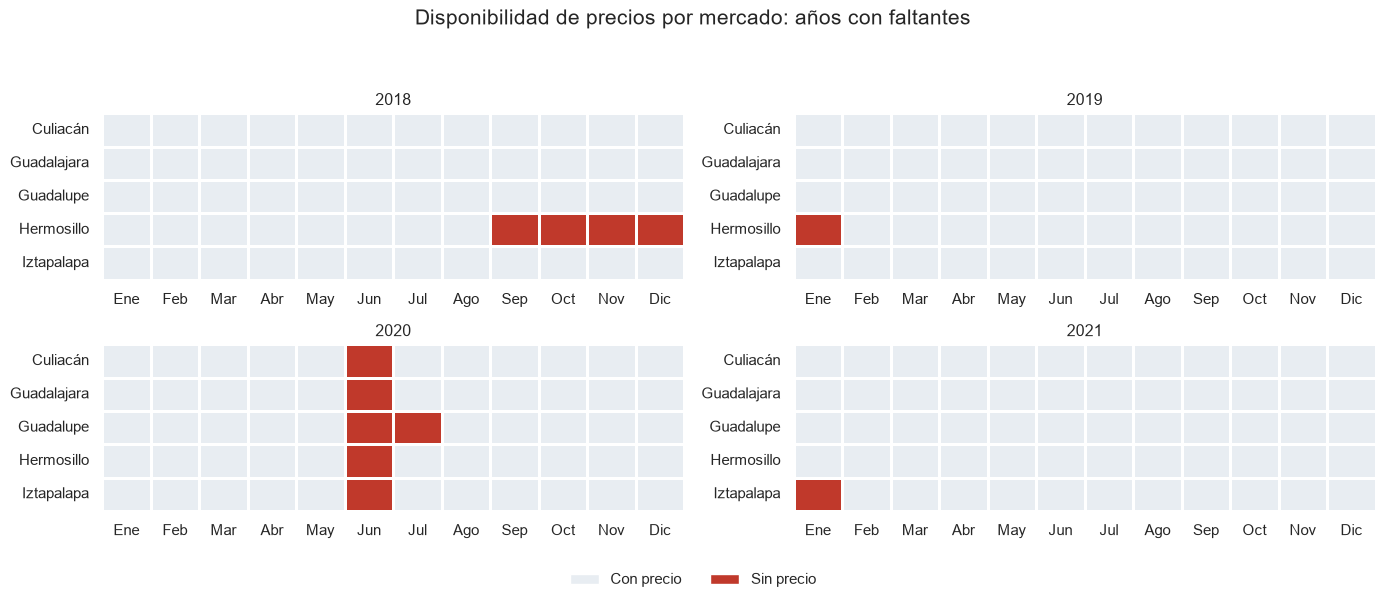

In [8]:
from matplotlib.patches import Patch

# Seleccionamos los años que contienen meses sin precio.
anios = sorted(meses_sin_precio["fecha"].dt.year.unique())
meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic",
]
colores = ["#e8edf2", "#c0392b"]

# Creamos un panel para cada año.
sns.set_theme(style="white", font_scale=0.95)
fig, ejes = plt.subplots(2, 2, figsize=(14, 6))

for anio, ax in zip(anios, ejes.flat):
    # Organizamos los meses del año por mercado.
    anual = cobertura_mensual.loc[
        cobertura_mensual["fecha"].dt.year == anio
    ].copy()
    anual["mes"] = anual["fecha"].dt.month

    matriz = anual.pivot(
        index="mercado",
        columns="mes",
        values="sin_precio",
    ).sort_index(axis=1)

    # Usamos los mismos colores y escala en todos los paneles.
    sns.heatmap(
        matriz.astype(int),
        cmap=colores,
        vmin=0,
        vmax=1,
        cbar=False,
        linewidths=1,
        linecolor="white",
        xticklabels=meses,
        yticklabels=True,
        ax=ax,
    )

    ax.set(title=str(anio), xlabel="", ylabel="")
    ax.tick_params(axis="both", labelrotation=0)

# Añadimos un título y una leyenda compartidos.
fig.suptitle(
    "Disponibilidad de precios por mercado: años con faltantes",
    fontsize=15,
)
fig.legend(
    handles=[
        Patch(facecolor=colores[0], label="Con precio"),
        Patch(facecolor=colores[1], label="Sin precio"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
)

fig.tight_layout(rect=(0, 0.07, 1, 0.93))
plt.show()

## 4 | Construcción del precio mensual por mercado

¿Cómo obtenemos un solo precio cuando existen varios
orígenes en un mismo mercado y mes?

Calcularemos el promedio simple de los precios disponibles,
asignando el mismo peso a cada origen. Conservaremos también
la cantidad de precios utilizados.

Si ningún origen tiene precio, el promedio permanecerá
como dato faltante.

### 4.1 | Promedio simple y cantidad de precios disponibles

In [9]:
# Calculamos el promedio y contamos los precios utilizados por mercado y mes.
precios_mensuales = (
    datos.groupby(["mercado", "fecha"], as_index=False)
    .agg(
        precio_promedio_mxn_kg=("precio_mxn_kg", "mean"),
        numero_precios=("precio_mxn_kg", "count"),
    )
)

# Observamos la estructura de la nueva tabla.
precios_mensuales.head(10)

,mercado,fecha,precio_promedio_mxn_kg,numero_precios
0,Culiacán,2013-01-01,4.50,1
1,Culiacán,2013-02-01,4.50,1
2,Culiacán,2013-03-01,4.70,1
3,Culiacán,2013-04-01,4.58,1
4,Culiacán,2013-05-01,4.00,1
5,Culiacán,2013-06-01,4.00,1
6,Culiacán,2013-07-01,4.00,1
7,Culiacán,2013-08-01,4.00,1
8,Culiacán,2013-09-01,4.25,2
9,Culiacán,2013-10-01,4.20,1


### 4.2 | Distribución de la cantidad de precios utilizados

In [10]:
# Contamos meses con cero, uno o varios precios disponibles.
precios_mensuales["numero_precios"].value_counts().sort_index()

numero_precios
0     12
1    746
2     21
3      1
Name: count, dtype: int64

### 4.3 | Comprobación del promedio con los registros por origen

In [11]:
# Consultamos los precios originales que participaron en este promedio.
datos.loc[
    (datos["mercado"] == "Culiacán")
    & (datos["fecha"] == "2013-09-01"),
    ["fecha", "mercado", "origen", "precio_mxn_kg"],
]

,fecha,mercado,origen,precio_mxn_kg
176,2013-09-01,Culiacán,Sinaloa,4.0
188,2013-09-01,Culiacán,Jalisco,4.5


## 5 | Análisis de las tendencias temporales
¿Qué tendencias, diferencias entre mercados y cambios abruptos aparecen durante 2013–2025?

### 5.1 | Evolución de los precios en paneles por mercado

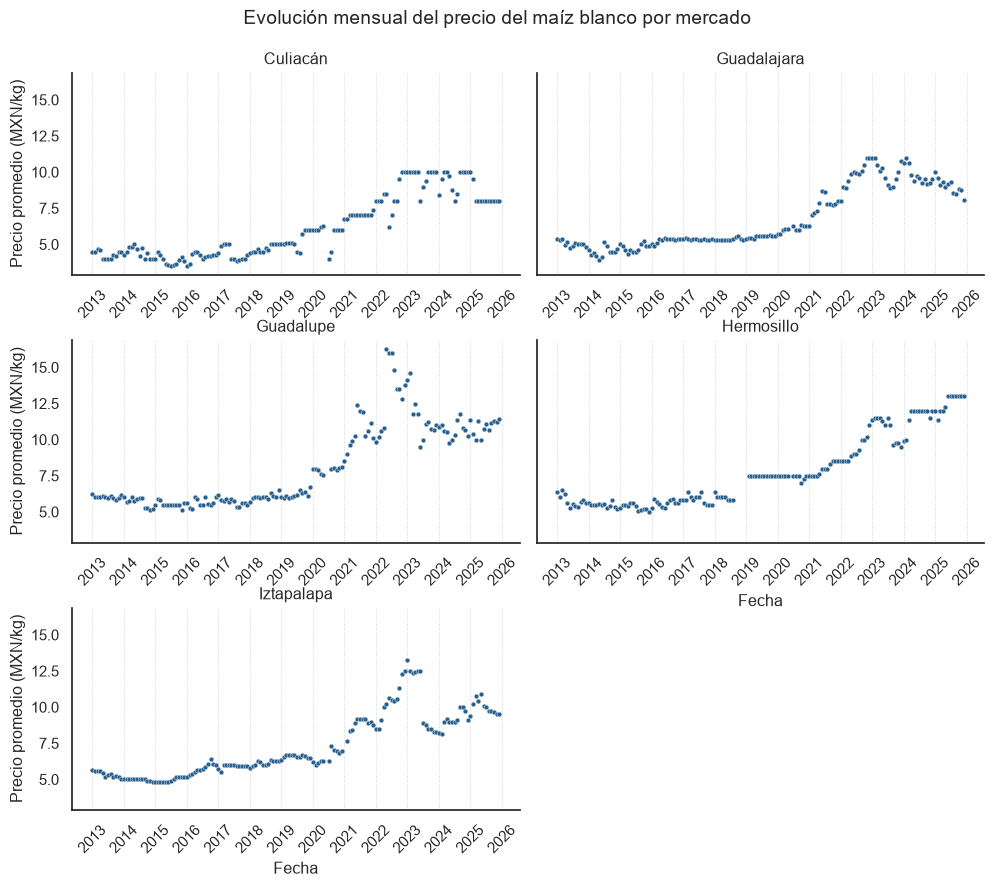

In [12]:
# Creamos un panel por mercado con sus precios mensuales.
grafica = sns.relplot(
    data=precios_mensuales,
    x="fecha",
    y="precio_promedio_mxn_kg",
    col="mercado",
    col_wrap=2,
    kind="scatter",
    height=2.8,
    aspect=1.8,
    s=12,
    color="#286090",
)

# Mantenemos escalas comunes para comparar los mercados.
grafica.set_axis_labels("Fecha", "Precio promedio (MXN/kg)")
grafica.set_titles("{col_name}")
grafica.figure.suptitle(
    "Evolución mensual del precio del maíz blanco por mercado",
    y=1.03,
)

import matplotlib.dates as mdates

# Marcamos cada año con una línea vertical tenue.
for ax in grafica.axes.flat:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_axisbelow(True)
    ax.grid(
        axis="x",
        linestyle=":",
        linewidth=0.7,
        color="gray",
        alpha=0.35,
    )
    ax.tick_params(axis="x", labelrotation=45, labelbottom=True)


plt.show()

Podemos observar tres patrones:
- Antes de 2020, los precios se mantienen en niveles estables y con fluctuaciones aparentemente moderadas.
- Entrr 2020 y 2023, aparece un aumento en los cinco mercados, aunque no con la misma intensidad y momento de estabilización.
- Después de los máximos, las trayectorias divergen: casi todos los mercados bajan un poco después del pico alrededor de 2023, mientras que Hermosillo continúa la tendencia de elevar los precios al final de cada año.

### 5.2 | Resumen descriptivo de los precios mensuales

¿Cuáles son los precios centrales, los extremos y la
variabilidad de cada mercado durante el periodo analizado?

In [13]:
# Resumimos los precios mensuales disponibles en cada mercado.
resumen_precios = precios_mensuales.groupby("mercado").agg(
    meses_con_precio=("precio_promedio_mxn_kg", "count"),
    media=("precio_promedio_mxn_kg", "mean"),
    mediana=("precio_promedio_mxn_kg", "median"),
    desviacion_estandar=("precio_promedio_mxn_kg", "std"),
    minimo=("precio_promedio_mxn_kg", "min"),
    maximo=("precio_promedio_mxn_kg", "max"),
)

resumen_precios.round(2)

,meses_con_precio,media,mediana,desviacion_estandar,minimo,maximo
mercado,,,,,,
Culiacán,155,6.12,5.00,2.14,3.50,10.00
Guadalajara,155,6.78,5.58,2.11,3.90,11.00
Guadalupe,154,8.12,6.23,2.85,5.12,16.25
Hermosillo,150,7.83,7.50,2.49,5.00,13.00
Iztapalapa,154,7.31,6.35,2.19,4.80,13.25


Lo que podemos observar a priori es:
- Guadalupe tiene la mayor media, el mayor máximo, el mayor mínimo y la mayor desviación estándar.
- Hermosillo cuenta con la mayor mediana.
- Culiacán presenta los menores valores de media, mediana y mínimo
- En todos los mercados, la media supera a la mediana.


### 5.3 | Comparación de las distribuciones mediante diagramas de caja

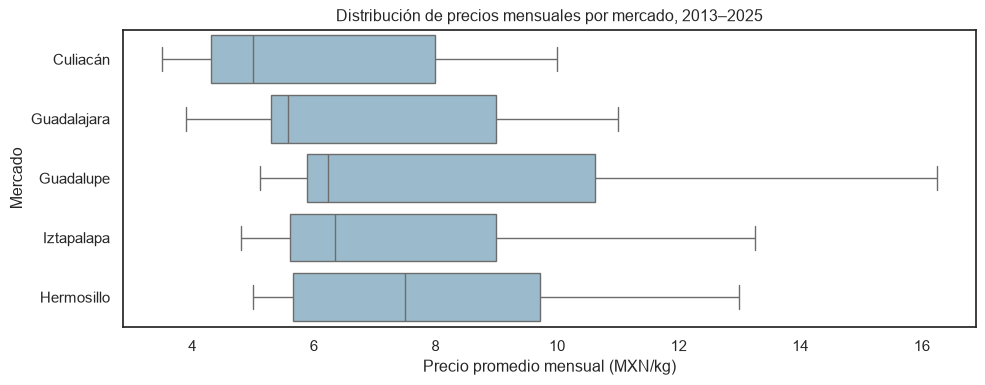

In [14]:
# Ordenamos los mercados según su precio mediano.
orden = resumen_precios.sort_values("mediana").index

# Comparamos las distribuciones de los precios mensuales.
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(
    data=precios_mensuales,
    x="precio_promedio_mxn_kg",
    y="mercado",
    order=orden,
    color="#93bdd5",
    whis=1.5,
    ax=ax,
)

ax.set_title("Distribución de precios mensuales por mercado, 2013–2025")
ax.set_xlabel("Precio promedio mensual (MXN/kg)")
ax.set_ylabel("Mercado")

fig.tight_layout()
plt.show()

En sí, tiene sentido que no existan datos atípicos, pues al estar revisando un periodo de 13 años completos de principio a fin, los saltos en precios pasan desapercibidos en esta gran ventana. Es por ello que mejor analizaremos las variaciones mensuales.


## 6 | Variaciones mensuales de los precios

### 6.1 | Cálculo de la variación respecto al mes anterior

¿En qué meses el precio aumentó o disminuyó con mayor intensidad respecto al mes anterior?

Esta variación la calcuremos así:

$$
\text{Variación mensual (\%)} = \left( \frac{\text{precio actual}}{\text{precio del mes anterior}} - 1 \right) \times 100
$$

In [15]:
# Ordenamos los registros cronológicamente dentro de cada mercado.
precios_mensuales = precios_mensuales.sort_values(
    ["mercado", "fecha"]
).copy()

# Calculamos variaciones por mercado sin rellenar los precios faltantes.
precios_mensuales["variacion_mensual_pct"] = (
    precios_mensuales.groupby("mercado")["precio_promedio_mxn_kg"]
    .pct_change(fill_method=None)
    .mul(100)
)

# Revisamos los precios y sus variaciones durante los primeros meses.
precios_mensuales[
    [
        "mercado",
        "fecha",
        "precio_promedio_mxn_kg",
        "variacion_mensual_pct",
    ]
].head(12)

,mercado,fecha,precio_promedio_mxn_kg,variacion_mensual_pct
0,Culiacán,2013-01-01,4.50,NaN
1,Culiacán,2013-02-01,4.50,0.000000
2,Culiacán,2013-03-01,4.70,4.444444
3,Culiacán,2013-04-01,4.58,-2.553191
4,Culiacán,2013-05-01,4.00,-12.663755
5,Culiacán,2013-06-01,4.00,0.000000
6,Culiacán,2013-07-01,4.00,0.000000
7,Culiacán,2013-08-01,4.00,0.000000
8,Culiacán,2013-09-01,4.25,6.250000
9,Culiacán,2013-10-01,4.20,-1.176471


La nueva columna es correcta:
- En enero aparece NaN, porque no tenemos diciembree de 2012 en el dataset
- Febrero tiene 0 porque el precio se mantuvo igual
- Marzo 4.44 % porque el precio aumentó ese porcentaje.
- Mayo -12.66 % porque el precio bajó abruptamente.

Analicemos las variaciones por mercado a continuación:

### 6.2 | Variaciones mensuales en paneles por mercado

¿cuándo aparecen los aumentos y disminuciones más pronunciados?

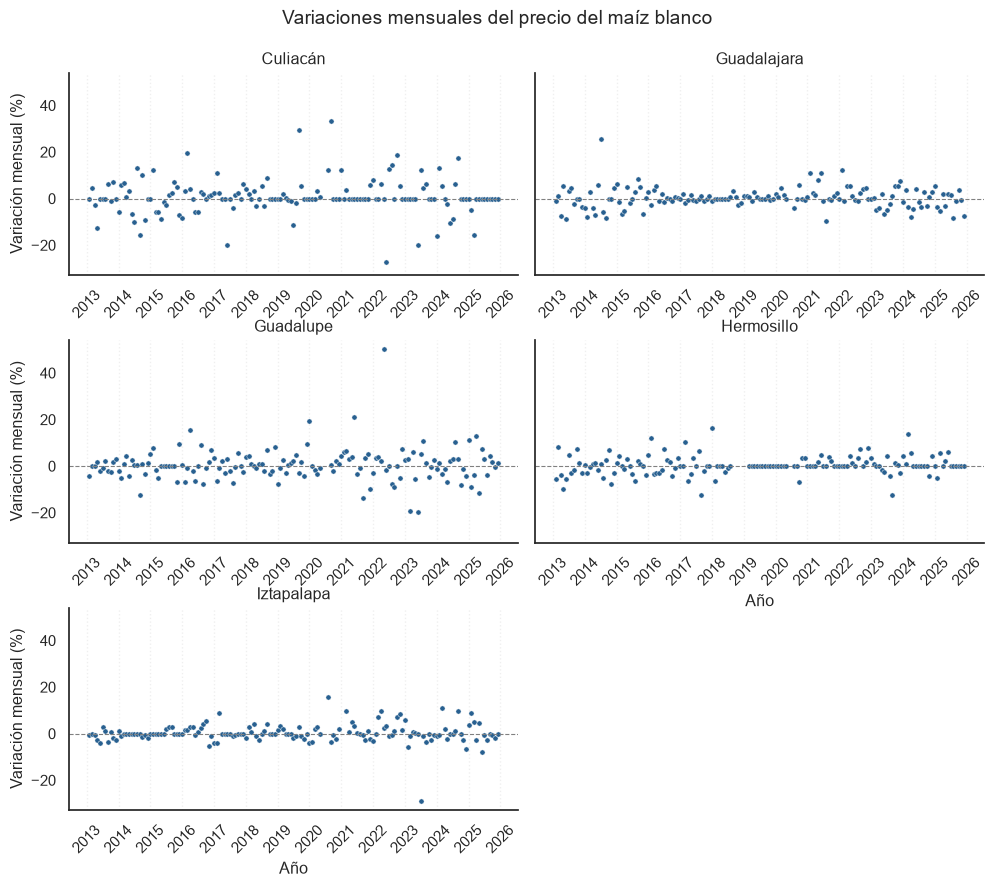

In [16]:
# Mostramos las variaciones mensuales en un panel por mercado.
grafica_variaciones = sns.relplot(
    data=precios_mensuales,
    x="fecha",
    y="variacion_mensual_pct",
    col="mercado",
    col_wrap=2,
    kind="scatter",
    height=2.8,
    aspect=1.8,
    s=14,
    color="#286090",
)

# Marcamos la ausencia de cambio y las referencias anuales.
for ax in grafica_variaciones.axes.flat:
    ax.axhline(
        0, color="gray", linestyle="--", linewidth=0.8
    )
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_axisbelow(True)
    ax.grid(axis="x", linestyle=":", alpha=0.3)
    ax.tick_params(axis="x", labelrotation=45, labelbottom=True)

grafica_variaciones.set_axis_labels("Año", "Variación mensual (%)")
grafica_variaciones.set_titles("{col_name}")
grafica_variaciones.figure.suptitle(
    "Variaciones mensuales del precio del maíz blanco",
    y=1.03,
)

plt.show()

Podemos distinguir cambios mensuales pronunciados en Culaicán, Guadalupe e Iztapalapa. En Hermosillo aparecen muchos meses donde no se movió el precio. Analizaremos posibles outliers por mercado basándonos en los meses.

### 6.3 | Comparación conjunta de las variaciones entre mercados

pero, ¿En qué meses coinciden o difieren los aumentos y las disminuciones entre mercados?

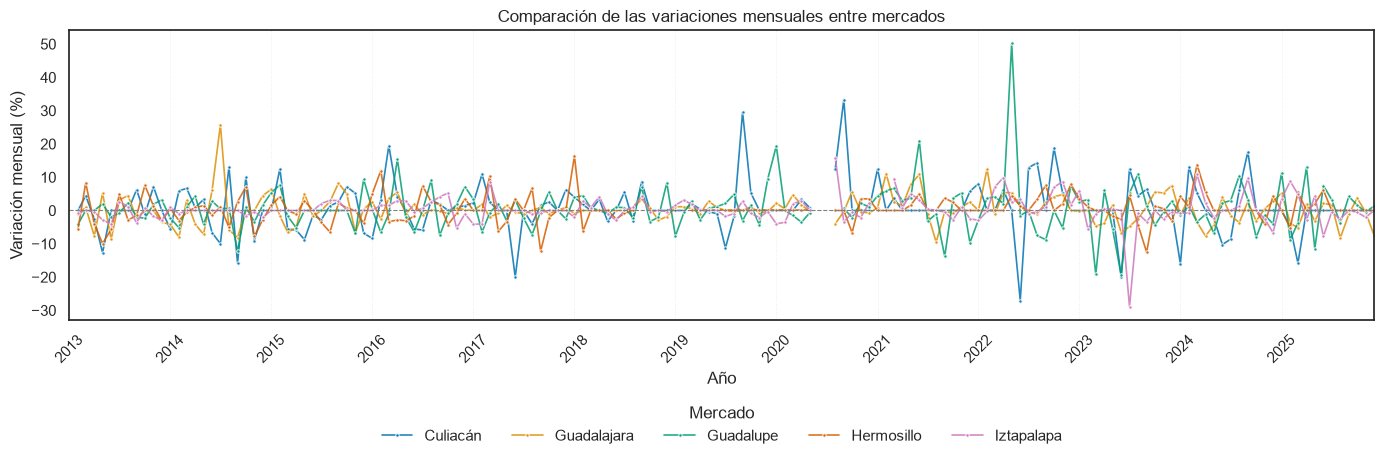

In [17]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns

# Ordenamos una copia de los datos para dibujar las series.
lineas_variaciones = precios_mensuales.sort_values(
    ["mercado", "fecha"]
).copy()

# Separamos los tramos para no conectar líneas a través de los faltantes.
lineas_variaciones["tramo"] = (
    lineas_variaciones.groupby("mercado")["variacion_mensual_pct"]
    .transform(lambda serie: serie.isna().cumsum())
)

# Dibujamos las variaciones de todos los mercados en una misma figura.
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(14, 5))

sns.lineplot(
    data=lineas_variaciones,
    x="fecha",
    y="variacion_mensual_pct",
    hue="mercado",
    units="tramo",
    estimator=None,
    errorbar=None,
    palette="colorblind",
    linewidth=1.2,
    marker="o",
    markersize=2.5,
    alpha=0.85,
    ax=ax,
)

# Añadimos referencias anuales y la línea de cambio cero.
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle=":", linewidth=0.7, alpha=0.35)
ax.tick_params(axis="x", labelrotation=45)
ax.set_xlim(
    lineas_variaciones["fecha"].min(),
    lineas_variaciones["fecha"].max(),
)

# Presentamos los títulos y la leyenda fuera del área de datos.
ax.set_title("Comparación de las variaciones mensuales entre mercados")
ax.set_xlabel("Año")
ax.set_ylabel("Variación mensual (%)")
# Colocamos la leyenda debajo para mantener visibles los cinco mercados.
ax.legend(
    title="Mercado",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=5,
    frameon=False,
)

fig.tight_layout()
plt.show()

## 7 | Detección y revisión de anomalías

### 7.1 | Primera técnica de detección: IQR

#### 7.1.1 | Cuartiles y límites por mercado

In [18]:
# Calculamos los cuartiles de las variaciones de cada mercado.
limites_iqr = (
    precios_mensuales.groupby("mercado")["variacion_mensual_pct"]
    .agg(
        q1=lambda serie: serie.quantile(0.25),
        q3=lambda serie: serie.quantile(0.75),
    )
)

# Construimos el rango intercuartílico y los límites de detección.
limites_iqr["iqr"] = limites_iqr["q3"] - limites_iqr["q1"]

limites_iqr["limite_inferior"] = (
    limites_iqr["q1"] - 1.5 * limites_iqr["iqr"]
)
limites_iqr["limite_superior"] = (
    limites_iqr["q3"] + 1.5 * limites_iqr["iqr"]
)

# Mostramos los límites como porcentajes de variación mensual.
limites_iqr.round(2)

,q1,q3,iqr,limite_inferior,limite_superior
mercado,,,,,
Culiacán,0.00,3.33,3.33,-5.00,8.33
Guadalajara,-1.29,2.44,3.73,-6.89,8.03
Guadalupe,-2.56,3.21,5.77,-11.22,11.86
Hermosillo,-0.70,1.66,2.36,-4.25,5.21
Iztapalapa,-0.93,1.61,2.54,-4.73,5.41


#### 7.1.2 | Identificación de candidatos fuera de los límites

Se puede observar que entre Culiacán y Hermosillo, ésta última tiene un rango más estrecho, por lo que un aumento de un mes a otro del 7 % sí sería outlier en Hermosillo, pero no en Culiacán. Veamos esto por cada mercado:

In [19]:
# Asociamos cada observación con los límites de su mercado.
revision_iqr = precios_mensuales.merge(
    limites_iqr.reset_index(),
    on="mercado",
    how="left",
    validate="many_to_one",
)

# Seleccionamos variaciones observadas que quedan fuera de los límites.
candidatos_iqr = revision_iqr.loc[
    revision_iqr["variacion_mensual_pct"].notna()
    & (
        (
            revision_iqr["variacion_mensual_pct"]
            < revision_iqr["limite_inferior"]
        )
        | (
            revision_iqr["variacion_mensual_pct"]
            > revision_iqr["limite_superior"]
        )
    ),
    [
        "mercado",
        "fecha",
        "variacion_mensual_pct",
        "limite_inferior",
        "limite_superior",
    ],
].copy()

# Redondeamos únicamente las columnas numéricas para mostrarlas.
vista_iqr = candidatos_iqr.copy()
columnas_numericas = vista_iqr.select_dtypes(include="number").columns

vista_iqr[columnas_numericas] = vista_iqr[columnas_numericas].round(2)

vista_iqr

,mercado,fecha,variacion_mensual_pct,limite_inferior,limite_superior
4,Culiacán,2013-05-01,-12.66,-5.00,8.33
12,Culiacán,2014-01-01,-5.56,-5.00,8.33
17,Culiacán,2014-06-01,-6.70,-5.00,8.33
18,Culiacán,2014-07-01,-9.97,-5.00,8.33
19,Culiacán,2014-08-01,13.10,-5.00,8.33
...,...,...,...,...,...
758,Iztapalapa,2024-03-01,10.84,-4.73,5.41
764,Iztapalapa,2024-09-01,9.65,-4.73,5.41
767,Iztapalapa,2024-12-01,-6.67,-4.73,5.41
769,Iztapalapa,2025-02-01,8.81,-4.73,5.41


#### 7.1.3 | Cantidad y proporción de candidatos por mercado

Al tener 104 candidatos a revisión, hay que resumirlos por mercado y porcentaje representado.

In [20]:
# Contamos las variaciones disponibles para evaluar en cada mercado.
resumen_iqr = precios_mensuales.groupby("mercado").agg(
    variaciones_evaluables=("variacion_mensual_pct", "count")
)

# Contamos los candidatos; cero significa que ninguno fue señalado.
resumen_iqr["candidatos_iqr"] = (
    candidatos_iqr.groupby("mercado")
    .size()
    .reindex(resumen_iqr.index, fill_value=0)
)

# Calculamos el porcentaje sobre las variaciones evaluables.
resumen_iqr["porcentaje_candidatos"] = (
    100
    * resumen_iqr["candidatos_iqr"]
    / resumen_iqr["variaciones_evaluables"]
)

resumen_iqr.round(2)

,variaciones_evaluables,candidatos_iqr,porcentaje_candidatos
mercado,,,
Culiacán,153,37,24.18
Guadalajara,153,14,9.15
Guadalupe,152,10,6.58
Hermosillo,147,27,18.37
Iztapalapa,151,16,10.60


Se puede ver que Culiacán es quien registra mayor proporción de candidatos, teniendo variaciones bruscas en 37 meses, le sigue Hermosillo con 27, mientras que Guadalupe es más discreto haciéndolo solamente 10 veces en su propia dimensión (su rango es más amplio).

#### 7.1.4 | Ordenamiento por magnitud de la variación

Veremos cuáles son los candidatos más grande tanto en aumentos abruptos como en disminuciones.

In [21]:
# Medimos el tamaño del cambio sin importar su dirección.
candidatos_ordenados = candidatos_iqr.copy()

candidatos_ordenados["magnitud_cambio"] = (
    candidatos_ordenados["variacion_mensual_pct"].abs()
)

# Ordenamos de mayor a menor magnitud.
candidatos_ordenados = candidatos_ordenados.sort_values(
    "magnitud_cambio",
    ascending=False,
)

# Revisamos los diez cambios más pronunciados.
candidatos_ordenados.head(10)

,mercado,fecha,variacion_mensual_pct,limite_inferior,limite_superior,magnitud_cambio
424,Guadalupe,2022-05-01,50.184843,-11.215173,11.861564,50.184843
92,Culiacán,2020-09-01,33.333333,-5.000000,8.333333,33.333333
80,Culiacán,2019-09-01,29.545455,-5.000000,8.333333,29.545455
750,Iztapalapa,2023-07-01,-28.960000,-4.732843,5.414404,28.960000
113,Culiacán,2022-06-01,-27.058824,-5.000000,8.333333,27.058824
174,Guadalajara,2014-07-01,25.755744,-6.887319,8.034830,25.755744
413,Guadalupe,2021-06-01,20.975610,-11.215173,11.861564,20.975610
53,Culiacán,2017-06-01,-20.000000,-5.000000,8.333333,20.000000
125,Culiacán,2023-06-01,-20.000000,-5.000000,8.333333,20.000000
38,Culiacán,2016-03-01,19.502075,-5.000000,8.333333,19.502075


#### 7.1.5 | Inspección de los precios y orígenes del caso de Guadalupe

Vemos que el mayor cambio señalado se sucitó en Guadalupe, en mayo de 2022, cuando con respecto a abril se vio un incremento del 50.18 %. La caída más importante fue Iztapalapa, cuando en julio de 2023 el precio cayó en 28.96 % con respecto al mes de junio. 

Queremos ver si el salto en los precios es de un mismo origin o si coincide con aquellos meses donde promediamos los precios al tener 2 o más orígenes, para esto veremos solamente el caso de Guadalupe:

In [22]:
# Consultamos los precios por origen antes y durante el mayor aumento.
caso_guadalupe = datos.loc[
    (datos["mercado"] == "Guadalupe")
    & datos["fecha"].between("2022-04-01", "2022-05-01"),
    ["fecha", "mercado", "origen", "precio_mxn_kg"],
].sort_values(["fecha", "origen"])

caso_guadalupe

,fecha,mercado,origen,precio_mxn_kg
915,2022-04-01,Guadalupe,Tamaulipas,10.82
916,2022-05-01,Guadalupe,Tamaulipas,16.25


##### 7.1.5.1 | Revisión de un candidato detectado mediante IQR

En Guadalupe, el precio aumentó de 10.82 a 16.25 MXN/kg
entre abril y mayo de 2022, una variación de 50.18 %.

Ambos registros corresponden al origen Tamaulipas y existe
un único precio disponible en cada mes. Por tanto, el aumento
no surge de promediar distintos orígenes.

Los valores coinciden con el HTML conservado del SNIIM.
En junio de 2022 el precio permanece elevado, en 16.00 MXN/kg.

Se conserva la observación y su identificación como candidato
IQR. El cotejo no permite determinar la causa económica del cambio.

### 7.2 | Segunda técnica de detección de anomalías: z-score

¿Qué variaciones mensuales se alejan más de tres desviaciones
estándar de la media de su mercado?

Aplicaremos este criterio exploratorio a las mismas variaciones
analizadas mediante IQR. Las observaciones señaladas se
conservarán para revisión.

$$
z = \frac{\text{variación mensual} - \text{media de las variaciones}}{\text{desviación estándar de las variaciones}}
$$

#### 7.2.1 | Media y desviación estándar de las variaciones

In [23]:
# Calculamos la media y desviación de las variaciones por mercado.
estadisticas_z = precios_mensuales.groupby("mercado").agg(
    media_variacion=("variacion_mensual_pct", "mean"),
    desviacion_variacion=("variacion_mensual_pct", "std"),
)

# Mostramos las estadísticas sin modificar su precisión original.
estadisticas_z.round(2)

,media_variacion,desviacion_variacion
mercado,,
Culiacán,0.95,7.59
Guadalajara,0.35,4.41
Guadalupe,0.59,7.09
Hermosillo,0.39,4.10
Iztapalapa,0.38,4.12


#### 7.2.2 | Cálculo del z-score y selección de candidatos

Vemos que Culiacán presenta un mayor promedio de variación entre sus datos, contando también con alta desviación estandar. Ahora calculemos el z-score de todos los meses y seleccionemos aquellos con |z| > 3:

In [24]:
# Asociamos cada observación con las estadísticas de su mercado.
revision_z = precios_mensuales.merge(
    estadisticas_z.reset_index(),
    on="mercado",
    how="left",
    validate="many_to_one",
)

# Calculamos la distancia respecto a la media en desviaciones estándar.
revision_z["z_score"] = (
    revision_z["variacion_mensual_pct"]
    - revision_z["media_variacion"]
) / revision_z["desviacion_variacion"]

# Seleccionamos variaciones evaluables cuyo z-score supera tres en magnitud.
candidatos_z = revision_z.loc[
    revision_z["z_score"].notna()
    & (revision_z["z_score"].abs() > 3),
    ["mercado", "fecha", "variacion_mensual_pct", "z_score"],
].copy()

# Mostramos los resultados con formato legible.
candidatos_z.style.format({
    "fecha": "{:%Y-%m}",
    "variacion_mensual_pct": "{:.2f}",
    "z_score": "{:.2f}",
})

,mercado,fecha,variacion_mensual_pct,z_score
80,Culiacán,2019-09,29.55,3.77
92,Culiacán,2020-09,33.33,4.27
113,Culiacán,2022-06,-27.06,-3.69
174,Guadalajara,2014-07,25.76,5.77
424,Guadalupe,2022-05,50.18,6.99
524,Hermosillo,2017-09,-12.19,-3.07
528,Hermosillo,2018-01,16.36,3.90
596,Hermosillo,2023-09,-12.55,-3.16
602,Hermosillo,2024-03,13.80,3.27
715,Iztapalapa,2020-08,15.87,3.76


#### 7.2.3 | Cantidad de candidatos detectados

In [25]:
len(candidatos_z)

11

### 7.3 | Comparación entre IQR y z-score

#### 7.3.1 | Coincidencias y diferencias por mercado

La técnica del z-score señaló únicamente 11 variaciones, frente a las 104 de la técncia del IQR. No significa que una técnica tenga un mejor método, sino que utilizan referencias y umbrales que difieren. Vemos cuáles coinciden:

In [26]:
# Comparamos los candidatos usando la clave mercado–mes.
comparacion_candidatos = candidatos_iqr[["mercado", "fecha"]].merge(
    candidatos_z[["mercado", "fecha"]],
    on=["mercado", "fecha"],
    how="outer",
    indicator=True,
    validate="one_to_one",
)

# Identificamos qué método señaló cada observación.
comparacion_candidatos["deteccion"] = (
    comparacion_candidatos["_merge"].map({
        "left_only": "Solo IQR",
        "right_only": "Solo z-score",
        "both": "Ambos",
    })
)

# Contamos las coincidencias y diferencias por mercado.
resumen_comparacion = pd.crosstab(
    comparacion_candidatos["mercado"],
    comparacion_candidatos["deteccion"],
).reindex(
    columns=["Solo IQR", "Solo z-score", "Ambos"],
    fill_value=0,
)

resumen_comparacion


deteccion,Solo IQR,Solo z-score,Ambos
mercado,,,
Culiacán,34,0,3
Guadalajara,13,0,1
Guadalupe,9,0,1
Hermosillo,23,0,4
Iztapalapa,14,0,2


La comparación confirma que los 11 candidatos de la técnica por z-score también fueron señalados por la de IQR:
- Ambos métodos: 11 casos.
- Solo IQR: 93 casos.
- Solo z-score: ninguno.
Con estos datos y umbrales, IQR señala más observaciones. Esto no demuestra que sus 93 candidatos adicionales sean errores ni falsas alarmas; requieren revisión.

#### 7.3.2 | Comparación gráfica de los candidatos

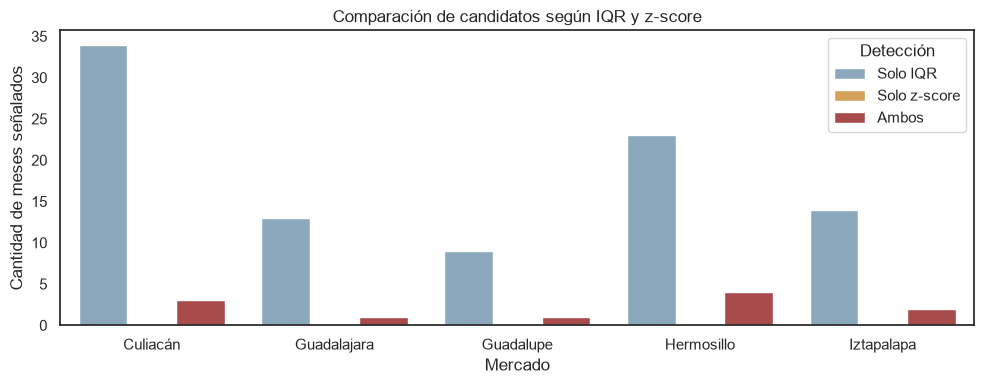

In [27]:
# Pasamos los conteos a formato largo para graficarlos.
comparacion_larga = resumen_comparacion.reset_index().melt(
    id_vars="mercado",
    var_name="deteccion",
    value_name="cantidad",
)

# Comparamos los resultados de detección por mercado.
fig, ax = plt.subplots(figsize=(10, 4))

sns.barplot(
    data=comparacion_larga,
    x="mercado",
    y="cantidad",
    hue="deteccion",
    hue_order=["Solo IQR", "Solo z-score", "Ambos"],
    palette={
        "Solo IQR": "#83a9c4",
        "Solo z-score": "#e6a34a",
        "Ambos": "#b83b3b",
    },
    ax=ax,
)

ax.set_title("Comparación de candidatos según IQR y z-score")
ax.set_xlabel("Mercado")
ax.set_ylabel("Cantidad de meses señalados")
ax.legend(title="Detección")

fig.tight_layout()
plt.show()

#### 7.3.3 | Síntesis de la comparación

IQR señaló unas 104 variaciones mensuales y el z-score señaló 11.
Las 11 observaciones identificadas mediante z-score también
fueron detectadas por el IQR. Aquí, los resultados, dependerán del umbral que selecciones para señalar como anomalías.

## 8 | Relaciones entre mercados del SNIIM

¿Qué asociación existe entre las variaciones mensuales
de los precios de los cinco mercados?

Esta exploración se limita a SNIIM y todavía no aborda
la relación con los rendimientos bursátiles de Gruma.

### 8.1 | Alineación de las variaciones por mes

In [28]:
# Organizamos un mes por fila y un mercado por columna.
variaciones_por_mercado = precios_mensuales.pivot(
    index="fecha",
    columns="mercado",
    values="variacion_mensual_pct",
).sort_index()

# Revisamos la tabla sin rellenar los faltantes.
variaciones_por_mercado.head(10)

mercado,Culiacán,Guadalajara,Guadalupe,Hermosillo,Iztapalapa
fecha,,,,,
2013-01-01,NaN,NaN,NaN,NaN,NaN
2013-02-01,0.000000,-1.119403,-4.153355,-5.660377,-0.709220
2013-03-01,4.444444,0.943396,0.000000,8.333333,0.000000
2013-04-01,-2.553191,-7.663551,0.000000,-4.000000,-0.357143
2013-05-01,-12.663755,5.263158,2.000000,-9.935897,-2.867384
2013-06-01,0.000000,-8.653846,-1.960784,-5.693950,-4.059041
2013-07-01,0.000000,3.157895,-0.666667,4.905660,2.692308
2013-08-01,0.000000,4.489796,2.348993,-2.877698,1.123596
2013-09-01,6.250000,-2.343750,-1.967213,-1.481481,-3.703704


### 8.2 | Meses disponibles para comparar mercados

¿Cuántos meses tienen variaciones disponibles simultáneamente
en cada pareja de mercados?

Este conteo permitirá interpretar las correlaciones considerando
la cantidad de observaciones utilizadas.

In [29]:
# Representamos la disponibilidad como uno y la ausencia como cero.
disponibilidad = variaciones_por_mercado.notna().astype(int)

# Contamos los meses con información simultánea en cada pareja.
meses_comparables = disponibilidad.T.dot(disponibilidad)

meses_comparables

mercado,Culiacán,Guadalajara,Guadalupe,Hermosillo,Iztapalapa
mercado,,,,,
Culiacán,153,153,152,147,151
Guadalajara,153,153,152,147,151
Guadalupe,152,152,152,146,150
Hermosillo,147,147,146,147,145
Iztapalapa,151,151,150,145,151


### 8.3 | Correlaciones entre las variaciones mensuales

¿Qué dirección e intensidad tienen las asociaciones entre mercados?

Calcularemos Pearson y Spearman utilizando los meses con
información disponible para cada pareja, sin imputar faltantes.
Las asociaciones son descriptivas y no representan efectos causales.

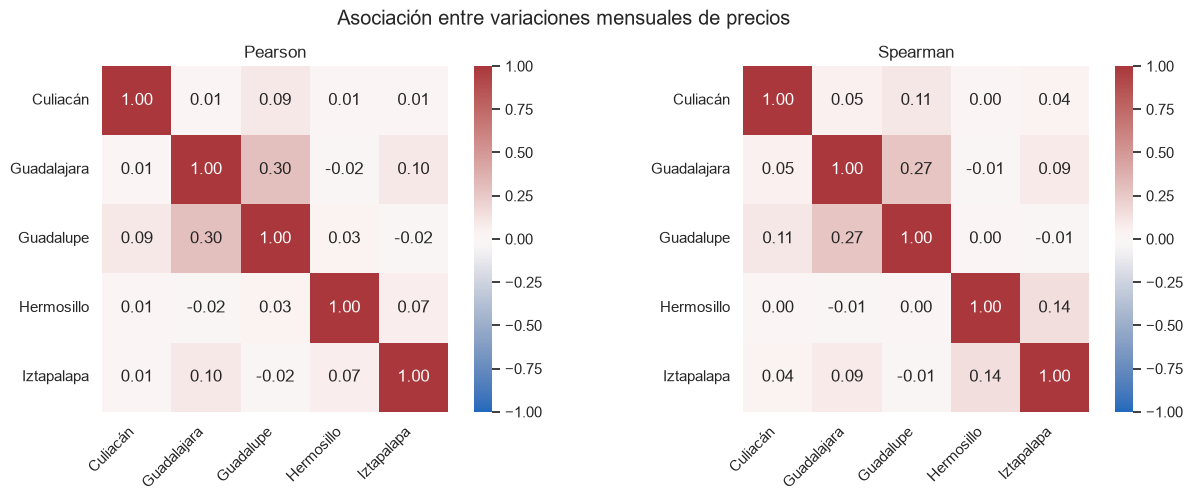

In [30]:
# Calculamos ambas correlaciones usando observaciones disponibles por pareja.
correlacion_pearson = variaciones_por_mercado.corr(method="pearson")
correlacion_spearman = variaciones_por_mercado.corr(method="spearman")

# Mostramos las matrices con una escala de colores común.
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

for ax, matriz, titulo in zip(
    ejes,
    [correlacion_pearson, correlacion_spearman],
    ["Pearson", "Spearman"],
):
    sns.heatmap(
        matriz,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax,
    )

    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

fig.suptitle("Asociación entre variaciones mensuales de precios")
fig.tight_layout()
plt.show()

#### 8.3.1 | Interpretación de las correlaciones

En general, las variaciones mensuales de los cinco mercados
presentan asociaciones contemporáneas bajas durante 2013–2025.

La pareja Guadalajara–Guadalupe registra la mayor asociación:
aproximadamente 0.30 mediante Pearson y 0.27 mediante Spearman.
Ambos coeficientes indican una asociación positiva de magnitud
limitada. Las demás parejas presentan valores cercanos a cero.

Que los precios compartan una tendencia creciente durante varios
años no implica que sus aumentos y disminuciones mensuales
coincidan estrechamente.

Las correlaciones utilizan únicamente los meses con información
disponible para cada pareja, según el conteo presentado previamente.


### 8.4 | Inspección visual de Guadalajara y Guadalupe

¿Cómo se distribuyen las variaciones de la pareja con mayor
correlación observada?

Cada punto representa un mismo mes con información disponible
en ambos mercados. Conservamos los valores extremos.

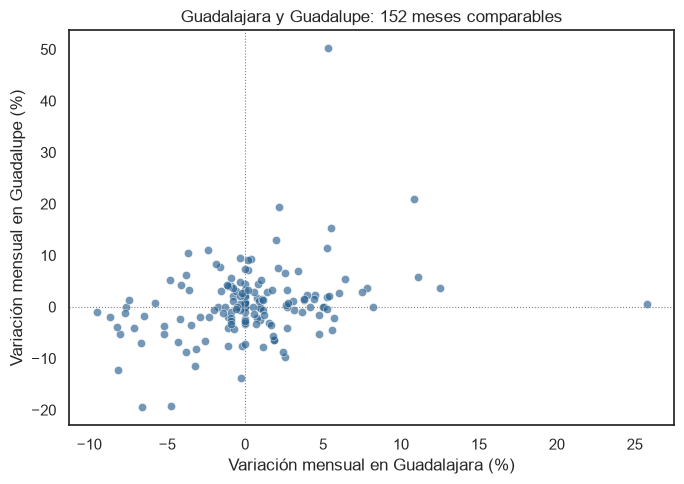

In [31]:
# Seleccionamos los meses comparables de esta pareja.
pareja = variaciones_por_mercado[
    ["Guadalajara", "Guadalupe"]
].dropna()

# Observamos la asociación entre las variaciones mensuales.
fig, ax = plt.subplots(figsize=(7, 5))

sns.scatterplot(
    data=pareja,
    x="Guadalajara",
    y="Guadalupe",
    s=35,
    alpha=0.65,
    color="#286090",
    ax=ax,
)

# Marcamos las referencias de ausencia de cambio.
ax.axhline(0, color="gray", linestyle=":", linewidth=0.8)
ax.axvline(0, color="gray", linestyle=":", linewidth=0.8)

ax.set_title(f"Guadalajara y Guadalupe: {len(pareja)} meses comparables")
ax.set_xlabel("Variación mensual en Guadalajara (%)")
ax.set_ylabel("Variación mensual en Guadalupe (%)")

fig.tight_layout()
plt.show()

#### 8.4.1 | Interpretación del diagrama de dispersión

Los meses comparables muestran una concentración de
variaciones cercanas a cero y una dispersión considerable.

La asociación positiva observada mediante Pearson y Spearman
es de magnitud limitada: las variaciones de ambos mercados
no mantienen una correspondencia estrecha mes a mes.

Se destacan algunos cambios extremos. Su presencia plantea
la necesidad de evaluar cuánto influyen en los coeficientes,
sin asumir que sean errores ni eliminarlos del análisis principal.

In [32]:
# Creamos un escenario alternativo sin modificar la pareja original.
pareja_sin_caso = pareja.drop(index=pd.Timestamp("2022-05-01"))

# Calculamos las matrices y extraemos la correlación entre ambos mercados.
metodos = ["pearson", "spearman"]

sensibilidad = pd.DataFrame(
    {
        f"Todos los meses ({len(pareja)})": [
            pareja.corr(method=metodo).loc["Guadalajara", "Guadalupe"]
            for metodo in metodos
        ],
        f"Sin mayo de 2022 ({len(pareja_sin_caso)})": [
            pareja_sin_caso.corr(method=metodo).loc[
                "Guadalajara", "Guadalupe"
            ]
            for metodo in metodos
        ],
    },
    index=["Pearson", "Spearman"],
)

sensibilidad.round(3)

,Todos los meses (152),Sin mayo de 2022 (151)
Pearson,0.30,0.303
Spearman,0.27,0.258


#### 8.4.2 | Sensibilidad al aumento de mayo de 2022

Comparamos las correlaciones entre Guadalajara y Guadalupe
utilizando los 152 meses disponibles y un escenario alternativo
que excluye mayo de 2022, con 151 observaciones.

Pearson pasa de aproximadamente 0.300 a 0.303 y Spearman
de 0.270 a 0.258. Los cambios son pequeños y se mantiene
la interpretación de una asociación positiva de magnitud limitada.

Esta comparación sugiere que el resultado no depende
principalmente del mes revisado. No demuestra estabilidad
frente a todos los valores extremos ni entre distintos periodos.